In [1]:
import zipfile
import io
import os

# Extract the main ZIP file
with zipfile.ZipFile('/content/bank+marketing.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/bank_data')

# Extract bank.zip
with zipfile.ZipFile('/content/bank_data/bank.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/bank_data/extracted')

# Check the extracted files
print(os.listdir('/content/bank_data/extracted'))

['bank-names.txt', 'bank-full.csv', 'bank.csv']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    '/content/bank_data/extracted/bank-full.csv',
    sep=';'
)

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

df.head(10)

Dataset loaded successfully!
Dataset dimensions: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


In [3]:
# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

# Display descriptive statistics
print("\nDescriptive statistics:")
display(df.describe(include='all'))

Dataset shape: (45211, 17)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  in

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,45211.000000,45211,45211,45211,45211,45211.000000,45211,45211,45211,45211.000000,45211,45211.000000,45211.000000,45211.000000,45211.000000,45211,45211
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,blue-collar,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,9732,27214,23202,44396,NaN,25130,37967,29285,NaN,13766,NaN,NaN,NaN,NaN,36959,39922
mean,40.936210,NaN,NaN,NaN,NaN,1362.272058,NaN,NaN,NaN,15.806419,NaN,258.163080,2.763841,40.197828,0.580323,NaN,NaN
std,10.618762,NaN,NaN,NaN,NaN,3044.765829,NaN,NaN,NaN,8.322476,NaN,257.527812,3.098021,100.128746,2.303441,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-8019.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,72.000000,NaN,NaN,NaN,8.000000,NaN,103.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,448.000000,NaN,NaN,NaN,16.000000,NaN,180.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,48.000000,NaN,NaN,NaN,NaN,1428.000000,NaN,NaN,NaN,21.000000,NaN,319.000000,3.000000,-1.000000,0.000000,NaN,NaN


In [4]:
# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical attributes:")
print(numerical_columns)

print("\nCategorical attributes:")
print(categorical_columns)

print("\nTarget attribute: y")

Numerical attributes:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical attributes:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

Target attribute: y


In [5]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check unknown entries
print("\nUnknown entries per column:")
for col in categorical_columns:
    unknown_count = (df[col] == 'unknown').sum()
    if unknown_count > 0:
        print(f"{col}: {unknown_count}")

# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check target distribution
print("\nTarget distribution:")
print(df['y'].value_counts())

print("\nTarget percentages:")
print(df['y'].value_counts(normalize=True).mul(100).round(2))

Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Unknown entries per column:
job: 288
education: 1857
contact: 13020
poutcome: 36959

Number of duplicate rows: 0

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [6]:
from sklearn.model_selection import train_test_split

# Remove duration to avoid using information unavailable before the call
X = df.drop(columns=['y', 'duration'])

# Target variable
y = df['y'].map({'no': 0, 'yes': 1})

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (36168, 15)
Testing features: (9043, 15)

Training target distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64


Subscription counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Subscription percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


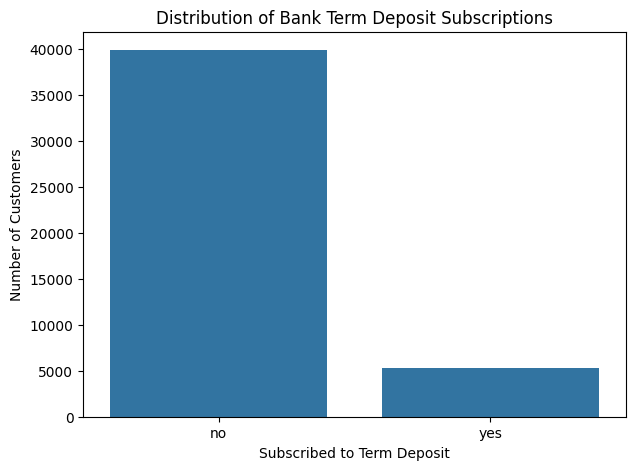

In [7]:
# Count customers in each target class
target_counts = df['y'].value_counts()

print("Subscription counts:")
print(target_counts)

print("\nSubscription percentages:")
print((df['y'].value_counts(normalize=True) * 100).round(2))

# Plot target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title('Distribution of Bank Term Deposit Subscriptions')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Number of Customers')

plt.show()

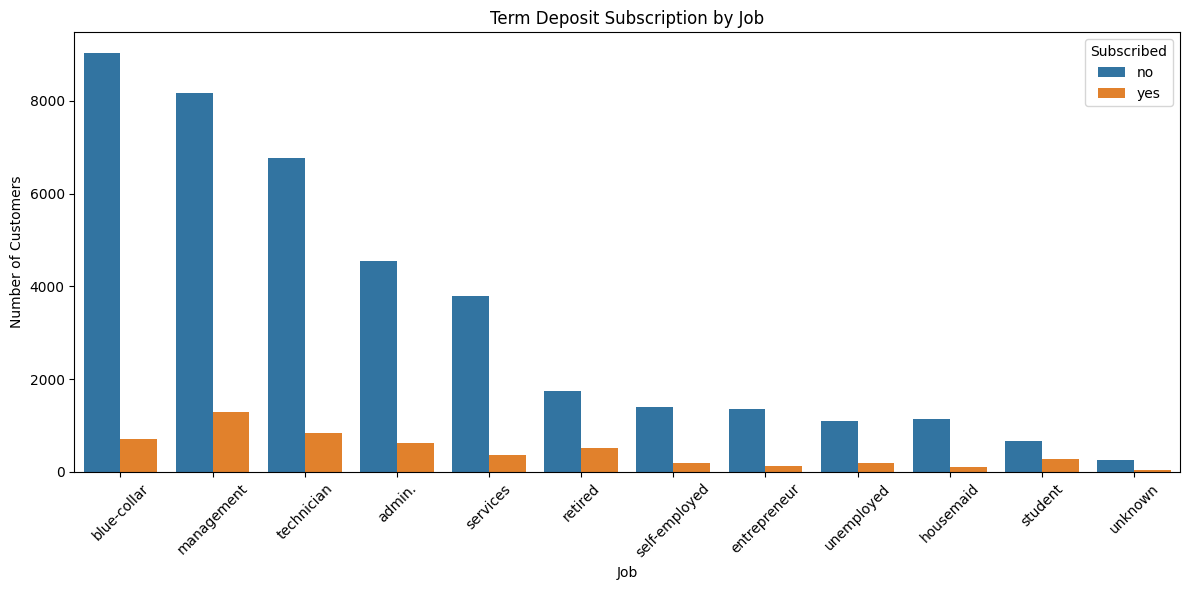

In [8]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='job',
    hue='y',
    order=df['job'].value_counts().index
)

plt.title('Term Deposit Subscription by Job')
plt.xlabel('Job')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)
plt.legend(title='Subscribed')

plt.tight_layout()
plt.show()

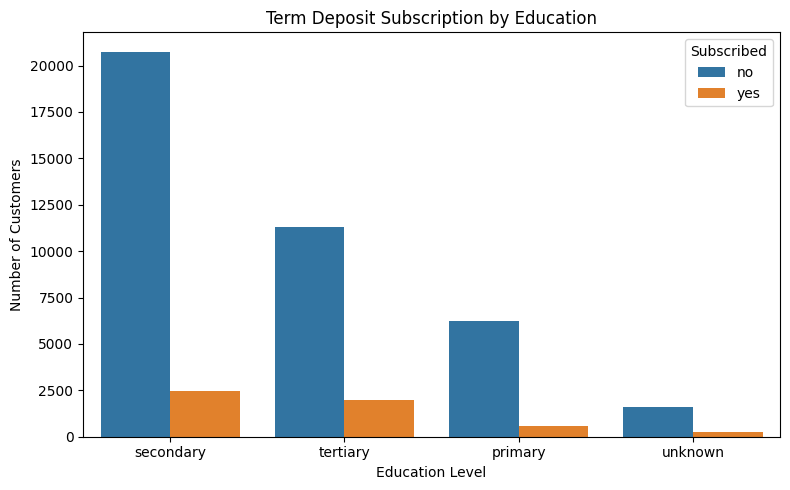

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='education',
    hue='y',
    order=df['education'].value_counts().index
)

plt.title('Term Deposit Subscription by Education')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')

plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

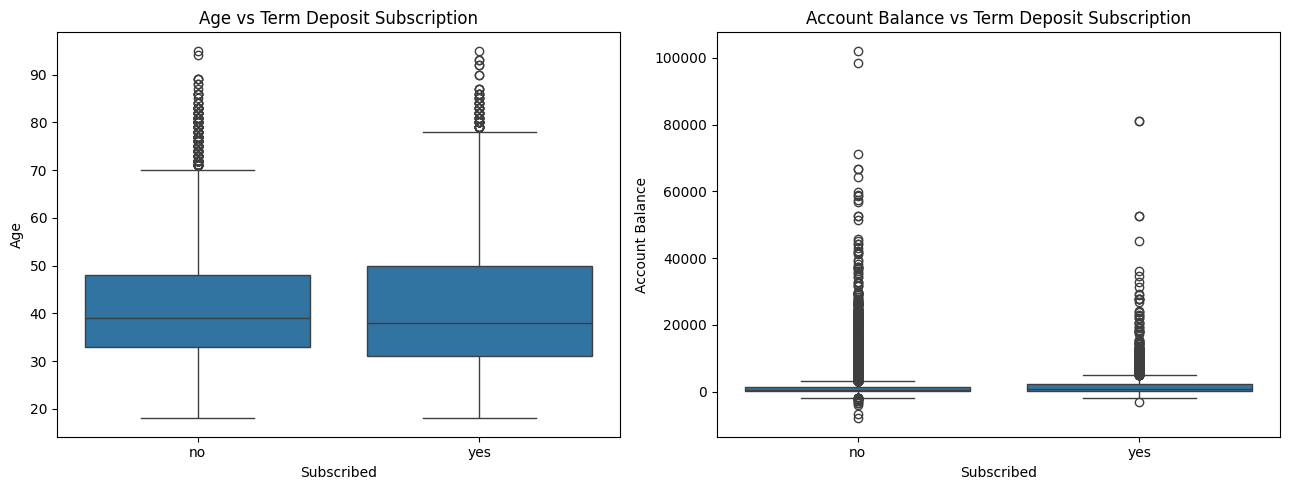

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df,
    x='y',
    y='age',
    ax=axes[0]
)

axes[0].set_title('Age vs Term Deposit Subscription')
axes[0].set_xlabel('Subscribed')
axes[0].set_ylabel('Age')

sns.boxplot(
    data=df,
    x='y',
    y='balance',
    ax=axes[1]
)

axes[1].set_title('Account Balance vs Term Deposit Subscription')
axes[1].set_xlabel('Subscribed')
axes[1].set_ylabel('Account Balance')

plt.tight_layout()
plt.show()

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify feature types from the training data
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Process numerical features
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Process categorical features
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully!")

Numerical features: 6
Categorical features: 9
Preprocessing pipeline created successfully!


In [12]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTarget classes:")
print(y_train.value_counts())

print("\nTarget mapping:")
print("0 = No subscription")
print("1 = Subscription")

Training data shape: (36168, 15)
Testing data shape: (9043, 15)

Target classes:
y
0    31937
1     4231
Name: count, dtype: int64

Target mapping:
0 = No subscription
1 = Subscription


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Define the four models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

# Train each model using the same preprocessing pipeline
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f'{name} trained successfully!')

print("\nAll four models trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
KNN trained successfully!
Random Forest trained successfully!

All four models trained successfully!


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, pipeline in trained_models.items():

    # Predict classes and probabilities
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'F1-Score': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df.round(4))

Model Evaluation Results:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7548,0.2662,0.6238,0.3732,0.7722
1,Decision Tree,0.8402,0.3059,0.2883,0.2968,0.6008
2,KNN,0.8874,0.5529,0.1975,0.2911,0.7027
3,Random Forest,0.8933,0.6332,0.2089,0.3141,0.7911


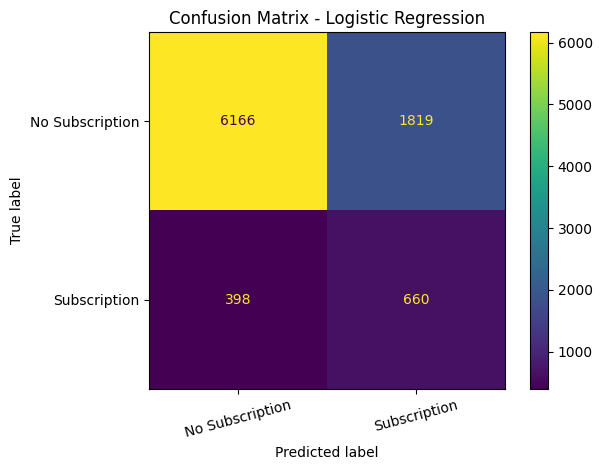

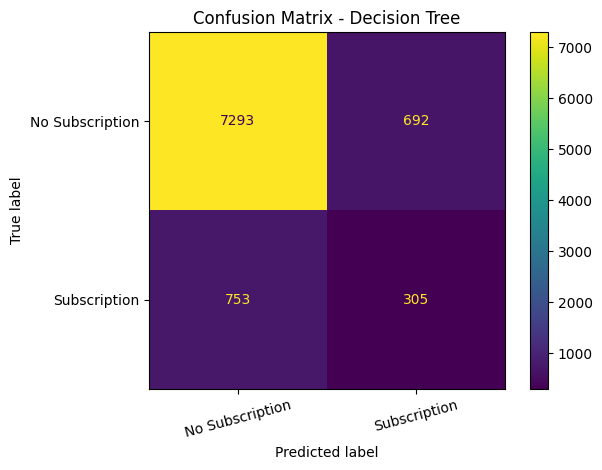

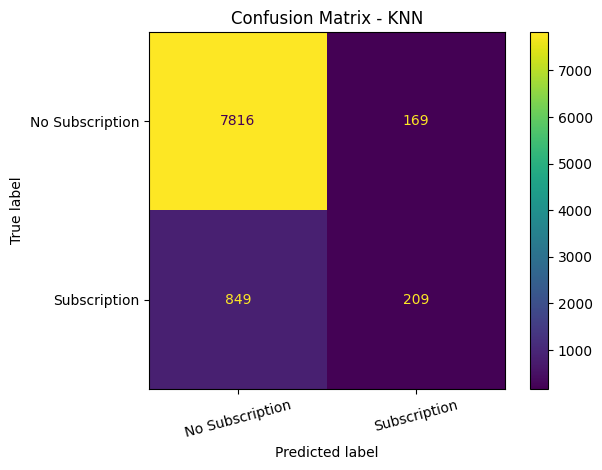

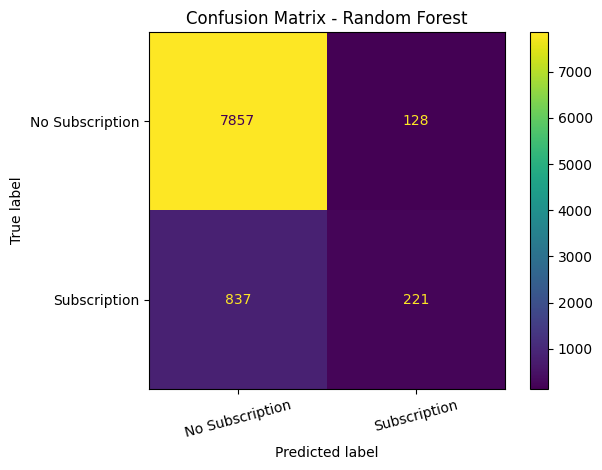

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, pipeline in trained_models.items():

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Subscription', 'Subscription']
    )

    display.plot()
    plt.title(f'Confusion Matrix - {name}')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

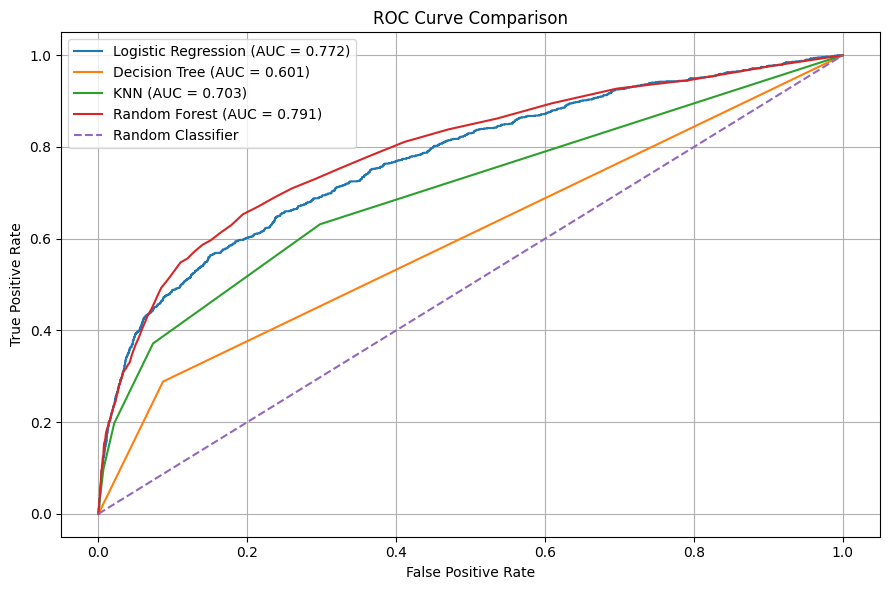

In [16]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for name, pipeline in trained_models.items():

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
results_df.to_csv('model_evaluation_results.csv', index=False)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [18]:
from google.colab import files

files.download('model_evaluation_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>